# Exercício – Predição com Regressão Linear Simples
## Quanto preciso estudar? Prevendo a nota final a partir das horas de estudo

**Aluno(a):** _preencher_  **RA:** _preencher_

## Parte 1 – Problema real e por que ele importa

No exercício anterior vi que horas de estudo e nota andam juntas. Agora quero **prever**:

> **Dado quantas horas por semana um aluno estuda (X), qual nota final (Y) ele deve tirar?**

- **Y = nota final (0 a 10)** → variável **contínua** → problema de **regressão**.
- **X = horas de estudo por semana** → um único preditor.

**Por que importa:** um aluno pode usar a previsão para planejar a semana ("quantas horas preciso para chegar perto de 7?"),
e a coordenação pode identificar cedo quem está estudando pouco e tende a ficar abaixo da média.

## Parte 2 – Dados usados e aulas/conceitos aplicados

**Origem:** dados **fictícios e coerentes** de 40 alunos (permitido pelo enunciado), gerados com semente fixa para que o resultado seja sempre o mesmo.
A regra usada para gerar foi "cada hora de estudo soma cerca de meio ponto, mais uma variação aleatória", o que é realista:
estudar ajuda, mas não explica tudo. Inseri de propósito **3 problemas de qualidade** (nulo, duplicata e valor impossível).

**Modelo escolhido (lista da seção 2.1):** **Regressão Linear Simples** – Y é contínuo e eu tenho **1 preditor**.
É o modelo mais simples que resolve o problema, como a Aula 09 recomenda.

| Aula | Conceito | Por que é pré-requisito para a predição |
|---|---|---|
| **Aula 09 – Predição** | Treino/teste 80/20, Regressão Linear Simples, MAE, RMSE, R² | É o modelo em si e a forma honesta de avaliá-lo (em dados que ele não viu) |
| **Aula 08 – Qualidade de Dados** | Tratar nulos, duplicatas e valores impossíveis | Um outlier como "nota 15" puxaria a reta inteira e estragaria o modelo |
| **Aula 03 – Estatística Descritiva** | Média, desvio padrão, correlação X–Y | Se não houvesse correlação, nem valeria a pena ajustar uma reta |
| **Aula 05 – Inferência** | p-valor do coeficiente angular | Verifica se a relação é real ou poderia ser acaso numa amostra pequena |
| **Aula 02 – Python** | Funções separando preparo, treino e avaliação | Deixa claro cada etapa e evita misturar dados de teste no treino |

## Parte 3 – Desenvolvimento
### 3.1 Gerando/carregando os dados

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

rng = np.random.default_rng(42)          # semente fixa -> resultados reproduzíveis
horas = rng.uniform(0, 12, 40).round(1)  # entre 0 e 12 horas por semana
nota = (3 + 0.5 * horas + rng.normal(0, 0.8, 40)).clip(0, 10).round(1)
df = pd.DataFrame({"aluno": [f"A{i:02d}" for i in range(1, 41)], "horas_estudo": horas, "nota": nota})

# Problemas de qualidade inseridos de propósito (como numa planilha real)
df.loc[5, "nota"] = np.nan                      # nota não lançada
df.loc[12, "nota"] = 15.0                       # valor impossível (escala é 0–10)
df = pd.concat([df, df.iloc[[20]]], ignore_index=True)  # linha duplicada

print(f"{len(df)} linhas")
df.head()

41 linhas


,aluno,horas_estudo,nota
0,A01,9.3,8.2
1,A02,5.3,6.1
2,A03,10.3,7.6
3,A04,8.4,7.4
4,A05,1.1,3.6


### 3.2 Preparo dos dados (Aula 08 – Qualidade) organizado em função (Aula 02 – Python)

In [2]:
def preparar_dados(df):
    """Remove nulos, duplicatas e notas fora da escala 0–10, mostrando o que foi removido."""
    print("Nulos:", df.isna().sum().sum())
    print("Duplicatas:", df.duplicated().sum())
    print("Notas fora de 0–10:", (~df["nota"].between(0, 10) & df["nota"].notna()).sum())
    limpo = df.dropna().drop_duplicates()
    limpo = limpo[limpo["nota"].between(0, 10) & limpo["horas_estudo"].between(0, 40)]
    print(f"Linhas: {len(df)} -> {len(limpo)}")
    return limpo.reset_index(drop=True)

df_limpo = preparar_dados(df)

Nulos: 1
Duplicatas: 1
Notas fora de 0–10: 1
Linhas: 41 -> 38


Removi as linhas problemáticas em vez de "inventar" valores. A nota 15 é provavelmente erro de digitação,
mas eu não sei qual seria o valor certo (1,5? 5?), então é mais seguro descartar. Fiquei com 38 alunos. A duplicata foi identificada pelo código do aluno (`aluno`), não só pelos valores: dois alunos diferentes podem, por coincidência, ter as mesmas horas e a mesma nota.

### 3.3 Antes de modelar: existe relação? (Aula 03 – Estatística Descritiva + Aula 05 – Inferência)

       horas_estudo   nota
count         38.00  38.00
mean           6.22   6.15
std            3.44   1.67
min            0.50   2.90
25%            3.00   4.82
50%            5.65   6.05
75%            9.25   7.60
max           11.60   9.10

Correlação horas x nota: 0.94


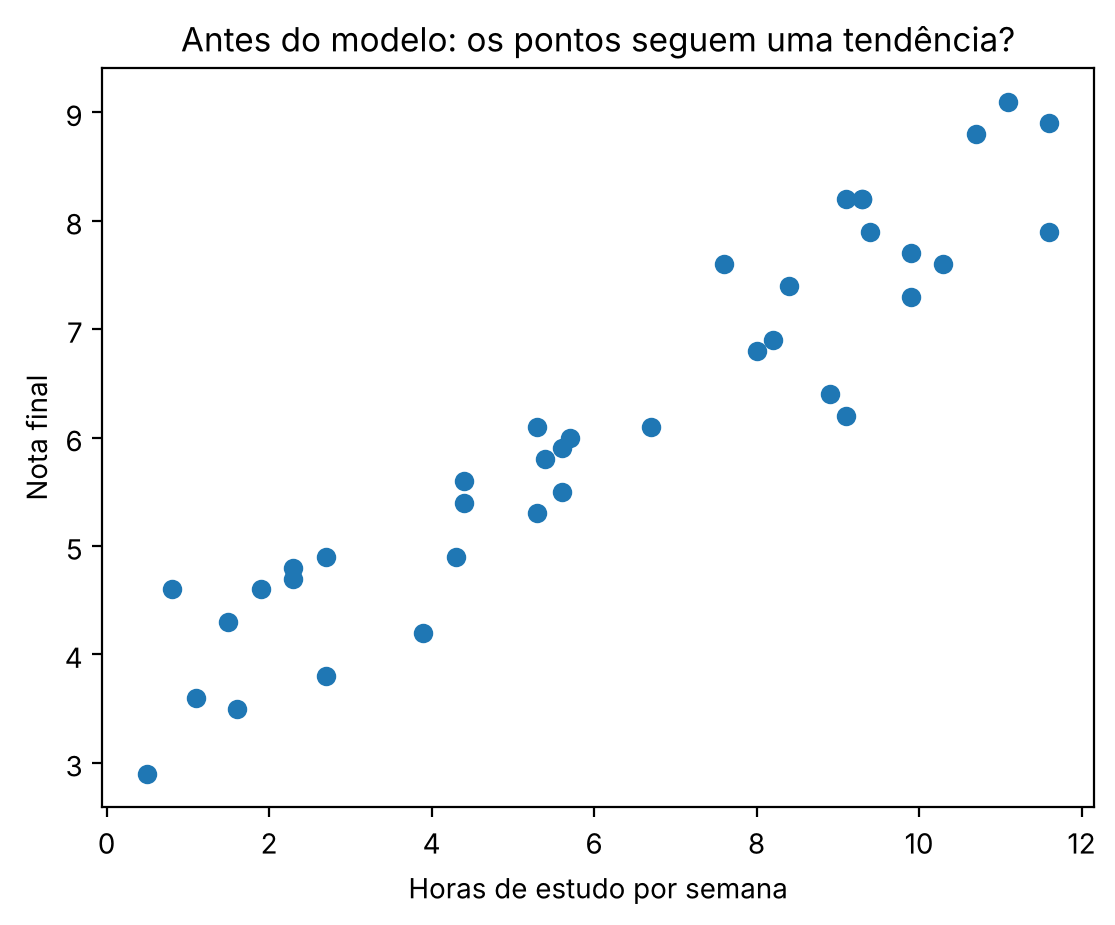

In [3]:
print(df_limpo.describe().round(2))
r = df_limpo["horas_estudo"].corr(df_limpo["nota"])
print(f"\nCorrelação horas x nota: {r:.2f}")

plt.scatter(df_limpo["horas_estudo"], df_limpo["nota"])
plt.xlabel("Horas de estudo por semana")
plt.ylabel("Nota final")
plt.title("Antes do modelo: os pontos seguem uma tendência?")
plt.show()

In [4]:
# Inferência: o coeficiente angular é estatisticamente diferente de zero?
teste = stats.linregress(df_limpo["horas_estudo"], df_limpo["nota"])
print(f"Inclinação: {teste.slope:.3f}  |  p-valor: {teste.pvalue:.2e}")
print("Relação significativa (p < 0,05)?", teste.pvalue < 0.05)

Inclinação: 0.459  |  p-valor: 5.31e-19
Relação significativa (p < 0,05)? True


A correlação é forte e positiva, e o p-valor é muito menor que 0,05: a relação **não** parece ser acaso.
Então faz sentido seguir para a predição.

### 3.4 Divisão treino/teste (80/20) e treino do modelo (Aula 09 – Predição)

In [5]:
def treinar(df):
    X = df[["horas_estudo"]]
    y = df["nota"]
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)
    modelo = LinearRegression().fit(X_tr, y_tr)
    return modelo, X_tr, X_te, y_tr, y_te

modelo, X_tr, X_te, y_tr, y_te = treinar(df_limpo)
print(f"Treino: {len(X_tr)} alunos | Teste: {len(X_te)} alunos")
print(f"Equação: nota = {modelo.intercept_:.2f} + {modelo.coef_[0]:.2f} × horas")

Treino: 30 alunos | Teste: 8 alunos
Equação: nota = 3.35 + 0.45 × horas


**Leitura da equação:** o intercepto (~3,4) é a nota prevista para quem não estuda nada fora da aula,
e cada hora semanal a mais soma cerca de **0,45 ponto** na nota prevista.

### 3.5 Avaliação com as métricas da Aula 09 (só nos dados de teste)

In [6]:
def avaliar(modelo, X_te, y_te):
    prev = modelo.predict(X_te)
    mae = mean_absolute_error(y_te, prev)
    rmse = np.sqrt(mean_squared_error(y_te, prev))
    r2 = r2_score(y_te, prev)
    print(f"MAE : {mae:.2f} ponto(s)")
    print(f"RMSE: {rmse:.2f} ponto(s)")
    print(f"R²  : {r2:.2f}")

avaliar(modelo, X_te, y_te)

MAE : 0.43 ponto(s)
RMSE: 0.50 ponto(s)
R²  : 0.88


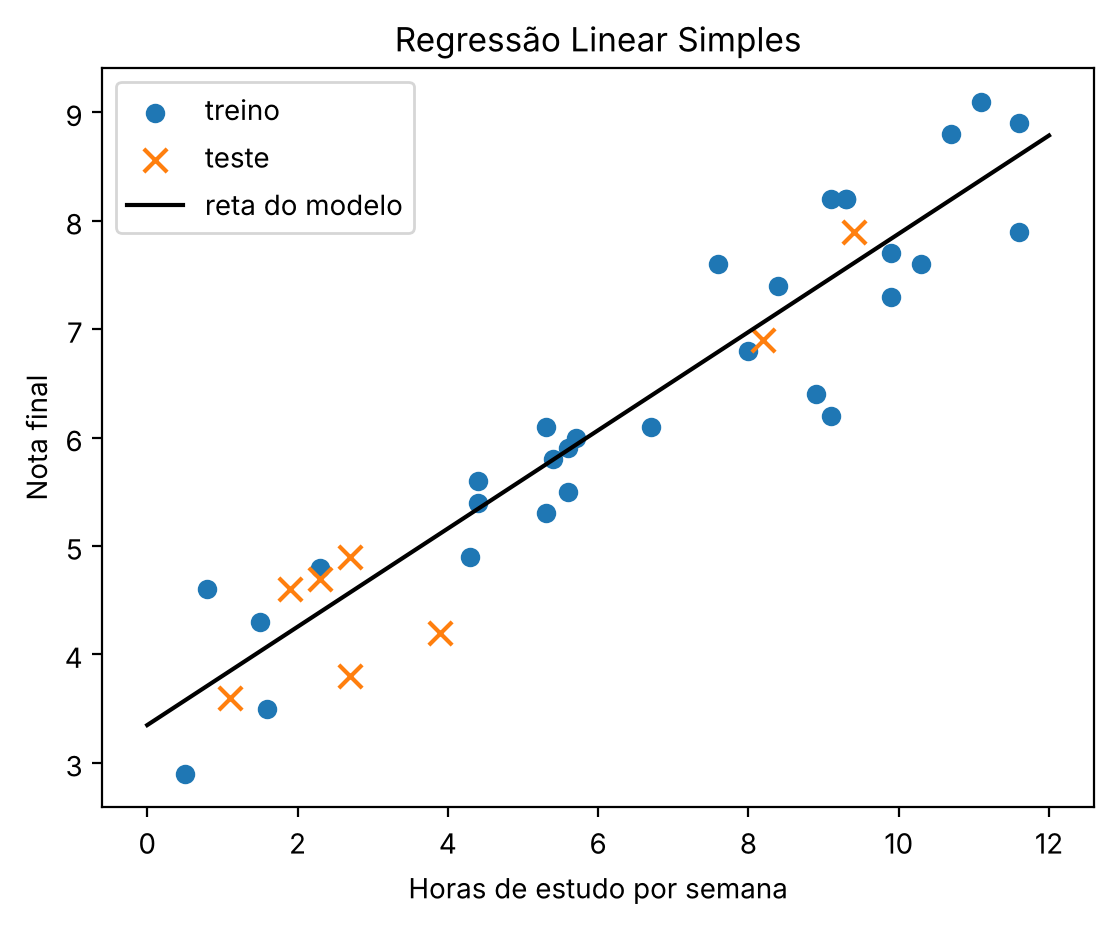

In [7]:
xs = np.linspace(0, 12, 50).reshape(-1, 1)
plt.scatter(X_tr, y_tr, label="treino")
plt.scatter(X_te, y_te, marker="x", s=70, label="teste")
plt.plot(xs, modelo.predict(pd.DataFrame(xs, columns=["horas_estudo"])), color="black", label="reta do modelo")
plt.xlabel("Horas de estudo por semana")
plt.ylabel("Nota final")
plt.legend()
plt.title("Regressão Linear Simples")
plt.show()

**Interpretação das métricas:**
- **MAE** ≈ erro médio, em pontos de nota: a previsão erra, em média, menos de 1 ponto.
- **RMSE** pune mais os erros grandes; como está próximo do MAE, não há erros muito fora do padrão.
- **R²** mostra quanto da variação das notas é explicada pelas horas de estudo. O resto vem de outros fatores
  (frequência, base anterior, dificuldade da matéria…) que o modelo não enxerga.

### 3.6 Usando o modelo

In [8]:
for h in [2, 5, 8]:
    p = modelo.predict(pd.DataFrame({"horas_estudo": [h]}))[0]
    print(f"Estudando {h} h/semana -> nota prevista ≈ {p:.1f}")

Estudando 2 h/semana -> nota prevista ≈ 4.3
Estudando 5 h/semana -> nota prevista ≈ 5.6
Estudando 8 h/semana -> nota prevista ≈ 7.0


## Parte 4 – Registro do uso de IA

**Ferramenta:** Claude (Anthropic)

**Prompt:**
> "Resolva esse [prints do enunciado do exercício de predição] e os textos sem ajuda de IA gostaria de algumas sugestões."

**Resposta (resumo):** a IA propôs prever a nota a partir das horas de estudo com Regressão Linear Simples,
gerou 40 alunos fictícios com 3 erros de qualidade, escreveu funções para preparo, treino e avaliação,
fez o teste de significância (p-valor), dividiu 80/20, calculou MAE, RMSE e R² e montou os gráficos.
Para a Parte 5, ela **não** escreveu a resposta – só deu um roteiro, porque o enunciado exige que seja sem IA.

**O que eu corrigi / completei / rejeitei e por quê:** _(preencher com o que VOCÊ fez de verdade)_
- _Ex.: conferi que o modelo escolhido está na lista permitida (2.1) e que não usei nada fora dela._
- _Ex.: verifiquei se a equação faz sentido calculando uma previsão na mão (intercepto + coef × horas)._
- _Ex.: notei que o modelo prevê nota acima de 10 para muitas horas de estudo e acrescentei isso como limite._

## Parte 5 – Resposta à pergunta obrigatória (SEM IA)

> ⚠️ Escrever com suas próprias palavras. Esta parte não foi escrita pela IA.

_Sua resposta:_

## Parte 6 – Conclusão

- **O que a predição significa:** com só uma informação (horas de estudo), dá para estimar a nota final com erro médio
  abaixo de 1 ponto. Um aluno que estuda ~2 h/semana tende a ficar perto de 4; com ~8 h/semana, perto de 7. Isso ajuda a planejar
  a rotina e a identificar alunos em risco.
- **Preparo foi essencial:** a nota 15 e a duplicata, se não fossem tratadas, distorceriam a reta.
- **Limites do modelo:**
  - **Extrapolação:** os dados de treino vão de 0 a 12 h/semana. Prever para 30 h daria nota acima de 10, o que é impossível.
    O modelo só vale dentro do intervalo que ele viu.
  - **Correlação não é causa:** quem estuda mais pode também faltar menos ou ter mais base. As horas não explicam tudo (veja o R²).
  - **Dados fictícios e amostra pequena:** com uma turma real o resultado pode ser diferente.